# Phase 4: Feature Engineering - The "Vitality Complexity Index"

In this phase, we translate clinical intuition into a programmable risk-scoring algorithm based on the LACE Index to flag high-risk diabetic patients prior to discharge.

In this phase,

1. Define modular scoring functions for Length of Stay (`L`), Acuity (`A`), Comorbidities (`C`), and Emergency Visits (`E`).
2. Programmatically calculate the total `VCI_Score` (`L + A + C + E`) for every patient encounter in `df`.
3. Categorize patients into three risk strata (`Low Risk`, `Medium Risk`, and `High Risk`) based on their `VCI_Score`.
4. Validate the algorithm by visualizing the 30-day readmission rate (`<30`) across each risk stratum.

# Step 4.1: Import Libraries and Load the Enriched Dataset

We import `pandas`, `matplotlib.pyplot`, and `seaborn`, then load the cleaned and enriched dataset (`diabetic_data_enriched.csv`) from the previous phases.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("data_files/diabetic_data_enriched.csv", low_memory=False)

print("Dataset shape:", df.shape)
display(df[['time_in_hospital', 'admission_type_id', 'number_diagnoses', 'number_emergency', 'readmitted']].head())

Dataset shape: (100114, 50)


,time_in_hospital,admission_type_id,number_diagnoses,number_emergency,readmitted
0,1,6,1,0,NO
1,3,1,9,0,>30
2,2,1,6,0,NO
3,2,1,7,0,NO
4,1,1,5,0,NO


# Step 4.2: Define VCI Component Scoring Functions

Instead of iterating row-by-row with `iterrows()`, we define four modular Python functions corresponding to the LACE scoring rules (`L`, `A`, `C`, and `E`) to apply efficiently across the DataFrame columns.

In [6]:
def calculate_L_points(days):
    if days < 1:
        return 0
    elif 1 <= days <= 4:
        return 1
    elif 5 <= days <= 13:
        return 4
    else:
        return 7


def calculate_A_points(adm_id):
    if int(adm_id) in [1, 7]:
        return 3
    else:
        return 0


def calculate_C_points(diag_count):
    if diag_count < 4:
        return 0
    elif 4 <= diag_count <= 7:
        return 3
    else:  
        return 5


def calculate_E_points(emerg_visits):
    if emerg_visits == 0:
        return 0
    elif 1 <= emerg_visits <= 4:
        return 3
    else: 
        return 5


# Step 4.3: Calculate `VCI_Score` for Every Patient

Apply the four component functions using `.apply()` and sum them (`VCI_Score = L + A + C + E`) to create the `VCI_Score` column.

In [7]:
L = df['time_in_hospital'].apply(calculate_L_points)
A = df['admission_type_id'].apply(calculate_A_points)
C = df['number_diagnoses'].apply(calculate_C_points)
E = df['number_emergency'].apply(calculate_E_points)


df['VCI_Score'] = L + A + C + E

display(df[['time_in_hospital', 'admission_type_id', 'number_diagnoses', 'number_emergency', 'VCI_Score']].head(10))

,time_in_hospital,admission_type_id,number_diagnoses,number_emergency,VCI_Score
0,1,6,1,0,1
1,3,1,9,0,9
2,2,1,6,0,7
3,2,1,7,0,7
4,1,1,5,0,7
5,3,2,9,0,6
6,4,3,7,0,4
7,5,1,8,0,12
8,13,2,8,0,9
9,12,3,8,0,9


## Step 4.4: Stratify Patients into Risk Categories

We categorize patients into three risk strata based on their VCI_Score: Low Risk (< 7), Medium Risk (7–10), and High Risk (> 10). A summary table is generated to inspect the distribution of encounters across each stratum.

In [10]:
def assign_risk_group(score):
    if score < 7:
        return "Low Risk"
    elif score <= 10:
        return "Medium Risk"
    else:
        return "High Risk"

df['VCI_Risk_Category'] = df['VCI_Score'].apply(assign_risk_group)

risk_order = ["Low Risk", "Medium Risk", "High Risk"]
risk_counts = df['VCI_Risk_Category'].value_counts().reindex(risk_order)

risk_summary_df = pd.DataFrame({
    'Risk Category': risk_counts.index,
    'Patient Count': risk_counts.values,
    'Percentage (%)': (risk_counts.values / len(df) * 100).round(2)
})

print("Patient Distribution by VCI Risk Category:")
display(risk_summary_df)

Patient Distribution by VCI Risk Category:


,Risk Category,Patient Count,Percentage (%)
0,Low Risk,28101,28.07
1,Medium Risk,52023,51.96
2,High Risk,19990,19.97


## Step 4.5: Validate VCI Model Using 30-Day Readmission Rates (<30)

Because the <30 readmission target class is imbalanced, raw encounter counts can obscure risk trends. We calculate normalized readmission rates (%) within each risk stratum using groupby and value_counts(normalize=True) and visualize the <30 readmission rate to verify whether high-risk patients experience higher return rates.

Readmission Rates (%) by VCI Risk Category:


readmitted,NO,>30,<30
VCI_Risk_Category,,,
Low Risk,59.76,31.44,8.81
Medium Risk,53.15,35.43,11.41
High Risk,43.87,41.41,14.73


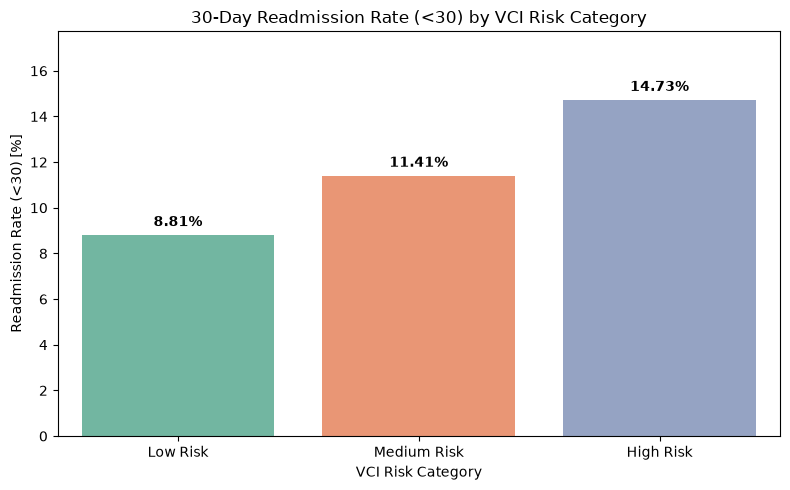

In [11]:
# calculate normalized readmission rates (%)
readmission_rates = (
    df.groupby('VCI_Risk_Category')['readmitted']
      .value_counts(normalize=True)
      .unstack()
      .reindex(index=risk_order, columns=['NO', '>30', '<30']) * 100
).round(2)

print("Readmission Rates (%) by VCI Risk Category:")
display(readmission_rates)

# extract <30 readmission rate
under_30_rates = readmission_rates['<30']

# plot bar chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=under_30_rates.index, y=under_30_rates.values, hue=under_30_rates.index, palette="Set2", legend=False)

# add percentage labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=4, fontweight='bold')

plt.title("30-Day Readmission Rate (<30) by VCI Risk Category")
plt.xlabel("VCI Risk Category")
plt.ylabel("Readmission Rate (<30) [%]")
plt.ylim(0, under_30_rates.max() + 3)
plt.tight_layout()
plt.show()

## Step 4.6: Phase 4 Output Verification

We perform a final check on df to confirm that VCI_Score and VCI_Risk_Category are populated and save the updated dataset for downstream reporting.

In [12]:
print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Is VCI_Score added:", 'VCI_Score' in df.columns)
print("Is VCI_Risk_Category added:", 'VCI_Risk_Category' in df.columns)

# save final enriched dataset with VCI features
df.to_csv("data_files/diabetic_data_vci.csv", index=False)
print("Saved updated dataset to data_files/diabetic_data_vci.csv")

Total rows: 100114
Total columns: 52
Is VCI_Score added: True
Is VCI_Risk_Category added: True
Saved updated dataset to data_files/diabetic_data_vci.csv


## Step 4.7: Phase 4 Summary & Key Takeaways

In this phase, we engineered the *Vitality Complexity Index (VCI_Score)* and stratified all 100,114 valid patient encounters into three clinical risk tiers (Low Risk, Medium Risk, and High Risk).

Key findings from the VCI validation:

1. *Effective Risk Segregation:* The 30-day readmission rate (<30) increases steadily from Low Risk (VCI < 7) to Medium Risk (VCI 7–10) and peaks in the High Risk (VCI > 10) group, confirming that the LACE-based VCI algorithm successfully identifies patients at highest risk of early return.
2. *Clinical Decision Support:* Nursing leadership and discharge planners can use VCI_Risk_Category before discharge to prioritize targeted interventions—such as medication reviews and 48-hour post-discharge follow-up calls—for High Risk patients.
3. *Final Analytical Dataset:* All cleaned records, scraped primary diagnosis descriptions, and engineered VCI features are saved in diabetic_data_vci.csv for final executive reporting.